# Geospatial Visualization of Measles Incidence in Saudi Arabia, 2014–2023

Geographic boundaries are provisionally reconstructed from governorate polygons and are not independently verified as official MOH health-region boundaries.

In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

# Project directories
data_dir = Path("../data")
geo_dir = Path("../geo_data")
figure_dir = Path("../figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Load surveillance data
regional = pd.read_csv(
    data_dir / "measles_region_year.csv"
)

# Load our cleaned geographic boundaries
health_regions = gpd.read_file(
    geo_dir / "provisional_health_regions.geojson"
)

# Basic validation
print("Surveillance observations:", len(regional))
print("Health regions in CSV:",
      regional["health_region"].nunique())
print("Geographic regions:", len(health_regions))
print("Total reported cases:",
      regional["reported_cases"].sum())
print("Geographic CRS:", health_regions.crs)

assert len(regional) == 200
assert regional["health_region"].nunique() == 20
assert len(health_regions) == 20
assert regional["reported_cases"].sum() == 5997
assert health_regions.geometry.is_valid.all()


Surveillance observations: 200
Health regions in CSV: 20
Geographic regions: 20
Total reported cases: 5997
Geographic CRS: EPSG:4326


In [4]:
############################################
### Calculate and attach the incidence rates


# Calculate AAIR for each health region
regional_aair = (
    regional.groupby("health_region", as_index=False)
    .agg(
        total_cases=("reported_cases", "sum"),
        population_exposure=("population", "sum")
    )
)

regional_aair["aair_per_100k"] = (
    regional_aair["total_cases"]
    / regional_aair["population_exposure"]
    * 100_000
)

# Join incidence data to geographic boundaries
measles_map = health_regions.merge(
    regional_aair,
    left_on="moh_health_region",
    right_on="health_region",
    how="left",
    validate="one_to_one"
)

# Validate the join
assert len(measles_map) == 20
assert measles_map["aair_per_100k"].notna().all()
assert measles_map["total_cases"].sum() == 5997

print("Geographic join successful.")
print("\nHighest-incidence health regions:")

display(
    measles_map[
        ["moh_health_region", "total_cases", "aair_per_100k"]
    ]
    .sort_values("aair_per_100k", ascending=False)
    .head(5)
)


Geographic join successful.

Highest-incidence health regions:


,moh_health_region,total_cases,aair_per_100k
16,Qurayyat,317,17.971540
2,Al-Jouf,567,15.967099
12,Najran,603,10.209054
10,Makkah,545,2.278438
8,Jazan,322,2.073670


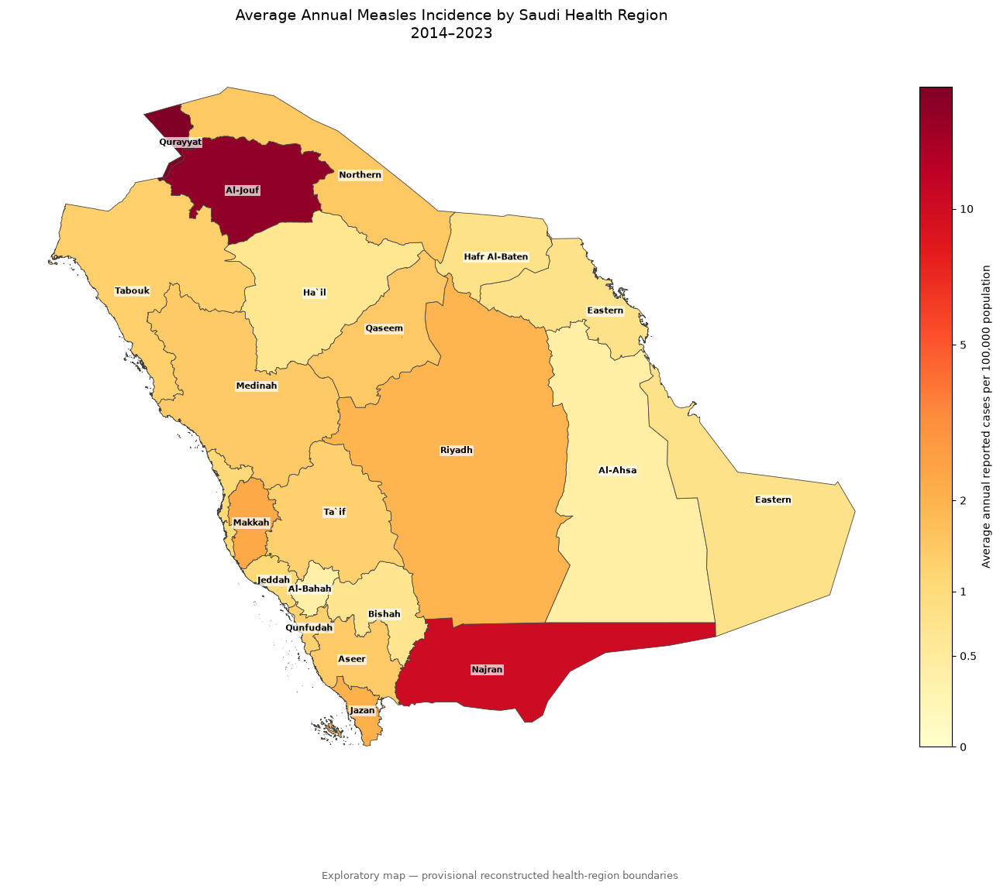

In [9]:

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

fig, ax = plt.subplots(figsize=(13, 12))

# Log-transformed colors, original incidence values retained
measles_map["aair_log"] = np.log1p(
    measles_map["aair_per_100k"]
)

norm = Normalize(
    vmin=0,
    vmax=np.log1p(measles_map["aair_per_100k"].max())
)

measles_map.plot(
    column="aair_log",
    ax=ax,
    cmap="YlOrRd",
    norm=norm,
    edgecolor="#444444",
    linewidth=0.6
)

# Label all 20 regions
for _, row in measles_map.iterrows():
    point = row.geometry.representative_point()

    ax.annotate(
        row["moh_health_region"],
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        color="black",
        bbox=dict(
            facecolor="white",
            alpha=0.7,
            edgecolor="none",
            pad=1
        )
    )

# Additional Eastern label near Dammam
# Both Eastern labels represent the SAME health region
eastern = measles_map.loc[
    measles_map["moh_health_region"] == "Eastern"
].geometry.iloc[0]

dammam_location = (50.10, 26.43)

assert eastern.covers(
    gpd.points_from_xy(
        [dammam_location[0]],
        [dammam_location[1]]
    )[0]
), "Dammam point falls outside the provisional Eastern polygon"

ax.annotate(
    "Eastern",
    xy=dammam_location,
    xytext=(-18, 12),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        alpha=0.7,
        edgecolor="none",
        pad=1
    )
)

# Colorbar: display original incidence units
sm = ScalarMappable(norm=norm, cmap="YlOrRd")
sm.set_array([])

cbar = fig.colorbar(
    sm, ax=ax, fraction=0.035, pad=0.025
)

ticks = np.array([0, 0.5, 1, 2, 5, 10])

cbar.set_ticks(np.log1p(ticks))
cbar.set_ticklabels([f"{x:g}" for x in ticks])
cbar.set_label(
    "Average annual reported cases per 100,000 population"
)

ax.set_title(
    "Average Annual Measles Incidence by Saudi Health Region\n"
    "2014–2023",
    fontsize=14,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.5, 0.025,
    "Exploratory map — provisional reconstructed health-region boundaries",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])
plt.show()


In [10]:
## 8.2 Annual Geographic Distribution of Measles Incidence (2014–2023)


# Join the 20 geographic regions with their annual incidence data
annual_geo = health_regions.merge(
    regional[
        [
            "health_region",
            "year",
            "reported_cases",
            "annual_incidence_per_100k"
        ]
    ],
    left_on="moh_health_region",
    right_on="health_region",
    how="left",
    validate="one_to_many"
)

# Validate the geographic dataset
print("Total geographic observations:", len(annual_geo))
print("Unique health regions:",
      annual_geo["moh_health_region"].nunique())
print("Years:", sorted(annual_geo["year"].unique()))
print("Total reported cases:",
      annual_geo["reported_cases"].sum())

assert len(annual_geo) == 200
assert annual_geo["year"].notna().all()
assert annual_geo["annual_incidence_per_100k"].notna().all()
assert annual_geo["reported_cases"].sum() == 5997

print("Annual geographic dataset validated.")


Total geographic observations: 200
Unique health regions: 20
Years: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Total reported cases: 5997
Annual geographic dataset validated.


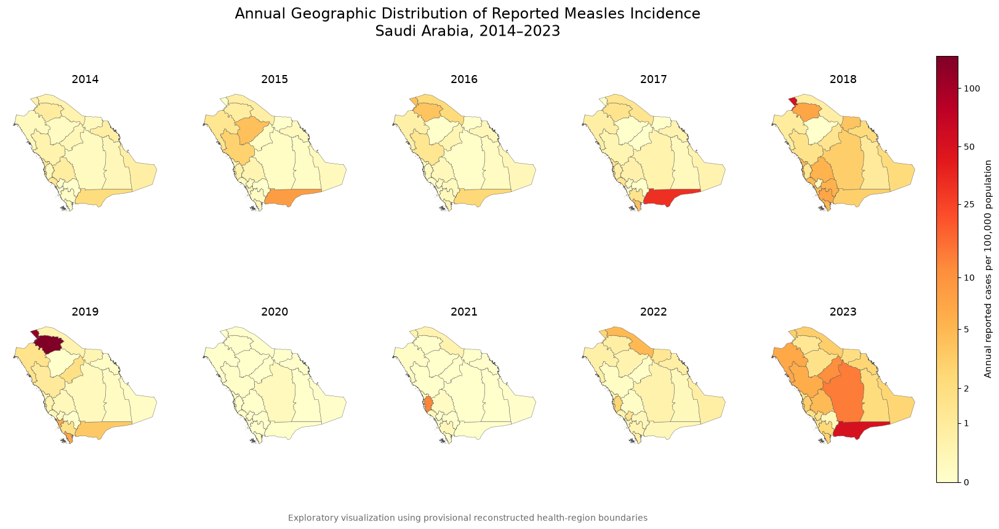

In [11]:

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

years = sorted(annual_geo["year"].unique())

# Shared color scale across all ten years
max_incidence = annual_geo["annual_incidence_per_100k"].max()

norm = Normalize(
    vmin=0,
    vmax=np.log1p(max_incidence)
)

fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(20, 9)
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    year_data = annual_geo[
        annual_geo["year"] == year
    ].copy()

    year_data["incidence_log"] = np.log1p(
        year_data["annual_incidence_per_100k"]
    )

    year_data.plot(
        column="incidence_log",
        cmap="YlOrRd",
        norm=norm,
        ax=ax,
        edgecolor="#555555",
        linewidth=0.3
    )

    ax.set_title(str(year), fontsize=13)
    ax.set_axis_off()

# Shared colorbar
sm = ScalarMappable(norm=norm, cmap="YlOrRd")
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.tolist(),
    fraction=0.025,
    pad=0.015
)

ticks = np.array([0, 1, 2, 5, 10, 25, 50, 100, 150])
valid_ticks = ticks[ticks <= max_incidence]

cbar.set_ticks(np.log1p(valid_ticks))
cbar.set_ticklabels([f"{x:g}" for x in valid_ticks])

cbar.set_label(
    "Annual reported cases per 100,000 population",
    fontsize=11
)

fig.suptitle(
    "Annual Geographic Distribution of Reported Measles Incidence\n"
    "Saudi Arabia, 2014–2023",
    fontsize=17,
    y=0.97
)

fig.text(
    0.5, 0.04,
    "Exploratory visualization using provisional reconstructed health-region boundaries",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.show()


In [12]:

fig.savefig(
    figure_dir / "measles_annual_geospatial_2014_2023.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_dir / "measles_annual_geospatial_2014_2023.svg",
    bbox_inches="tight"
)

print("Annual geographic maps saved.")


Annual geographic maps saved.


In [13]:
##################################
# Interactive Geographic Visualization of Measles Incidence (2014–2023).
###################################

In [14]:

import plotly.express as px
import json

# Work with the same provisional boundaries
interactive_geo = annual_geo.copy()

# Ensure year values are ordinary integers
interactive_geo["year"] = interactive_geo["year"].astype(int)

# Use a logarithmic transformation for map colors
interactive_geo["incidence_log"] = np.log1p(
    interactive_geo["annual_incidence_per_100k"]
)

# Convert regional boundaries to GeoJSON
boundary_geojson = json.loads(
    health_regions.to_json()
)

# Check the dataset
print("Observations:", len(interactive_geo))
print("Health regions:",
      interactive_geo["moh_health_region"].nunique())
print("Years:",
      interactive_geo["year"].nunique())

print("GeoJSON geographic features:",
      len(boundary_geojson["features"]))


Observations: 200
Health regions: 20
Years: 10
GeoJSON geographic features: 20


In [19]:

import plotly.graph_objects as go
from plotly.colors import sample_colorscale
import numpy as np

# Test year
test_year = 2019

year_data = annual_geo[
    annual_geo["year"] == test_year
].copy()

# Fixed color scale based on all years
max_incidence = annual_geo[
    "annual_incidence_per_100k"
].max()

fig_test = go.Figure()

for _, row in year_data.iterrows():

    geometry = row.geometry
    incidence = row["annual_incidence_per_100k"]

    # Normalize transformed incidence to 0–1
    color_value = (
        np.log1p(incidence) /
        np.log1p(max_incidence)
    )

    color = sample_colorscale(
        "YlOrRd", [float(color_value)]
    )[0]

    # Handle both Polygon and MultiPolygon
    parts = (
        list(geometry.geoms)
        if geometry.geom_type == "MultiPolygon"
        else [geometry]
    )

    for part in parts:
        x, y = part.exterior.xy

        fig_test.add_trace(
            go.Scatter(
                x=list(x),
                y=list(y),
                mode="lines",
                fill="toself",
                fillcolor=color,
                line=dict(
                    color="#444444",
                    width=0.7
                ),
                name=row["moh_health_region"],
                hovertemplate=(
                    f"<b>{row['moh_health_region']}</b>"
                    f"<br>Year: {test_year}"
                    f"<br>Cases: {row['reported_cases']}"
                    f"<br>Incidence: {incidence:.2f}"
                    "<br>per 100,000 population"
                    "<extra></extra>"
                ),
                showlegend=False
            )
        )

# Add health-region labels
label_points = health_regions.representative_point()

fig_test.add_trace(
    go.Scatter(
        x=label_points.x,
        y=label_points.y,
        text=health_regions["moh_health_region"],
        mode="text",
        textfont=dict(
            size=10,
            color="black"
        ),
        hoverinfo="skip",
        showlegend=False
    )
)

fig_test.update_layout(
    title=f"Measles Incidence by Health Region — {test_year}",
    width=950,
    height=850,
    paper_bgcolor="white",
    plot_bgcolor="white",
    xaxis=dict(
        visible=False,
        scaleanchor="y",
        scaleratio=1
    ),
    yaxis=dict(visible=False),
    margin=dict(l=20, r=20, t=70, b=20)
)

fig_test.show()


In [24]:

import plotly.graph_objects as go
from plotly.colors import sample_colorscale
import numpy as np

years = list(range(2014, 2024))

# Fixed scale across all years
max_incidence = annual_geo["annual_incidence_per_100k"].max()
max_log = np.log1p(max_incidence)

# One row per region and year
annual_lookup = annual_geo.set_index(
    ["year", "moh_health_region"]
)

# Build fixed polygon traces
regions = health_regions.set_index("moh_health_region")

polygon_parts = []

for region, row in regions.iterrows():
    geometry = row.geometry
    parts = (
        list(geometry.geoms)
        if geometry.geom_type == "MultiPolygon"
        else [geometry]
    )

    for part in parts:
        polygon_parts.append((region, part))

def incidence_color(incidence):
    value = np.log1p(incidence) / max_log
    return sample_colorscale("YlOrRd", [float(value)])[0]

def make_hover(region, year):
    record = annual_lookup.loc[(year, region)]
    return (
        f"<b>{region}</b>"
        f"<br>Year: {year}"
        f"<br>Reported cases: {int(record['reported_cases'])}"
        f"<br>Incidence: {record['annual_incidence_per_100k']:.2f}"
        "<br>cases per 100,000"
    )

fig_interactive = go.Figure()

# Initial year: 2014
for region, part in polygon_parts:
    record = annual_lookup.loc[(2014, region)]
    x, y = part.exterior.xy

    fig_interactive.add_trace(
        go.Scatter(
            x=list(x),
            y=list(y),
            mode="lines",
            fill="toself",
            fillcolor=incidence_color(
                record["annual_incidence_per_100k"]
            ),
            line=dict(color="#444444", width=0.7),
            text=make_hover(region, 2014),
            hovertemplate="%{text}<extra></extra>",
            showlegend=False
        )
    )

polygon_count = len(polygon_parts)

# Label layer: remains unchanged during animation
label_points = health_regions.representative_point()

fig_interactive.add_trace(
    go.Scatter(
        x=label_points.x,
        y=label_points.y,
        text=health_regions["moh_health_region"],
        mode="text",
        textfont=dict(size=10, color="black"),
        hoverinfo="skip",
        showlegend=False
    )
)

# Shared colorbar using the original incidence units
ticks = np.array([0, 1, 2, 5, 10, 25, 50, 100, 150])
ticks = ticks[ticks <= max_incidence]

fig_interactive.add_trace(
    go.Scatter(
        x=[None],
        y=[None],
        mode="markers",
        marker=dict(
            size=1,
            color=[0],
            cmin=0,
            cmax=max_log,
            colorscale="YlOrRd",
            showscale=True,
            colorbar=dict(
                title="Cases per 100,000",
                tickvals=np.log1p(ticks).tolist(),
                ticktext=[f"{t:g}" for t in ticks]
            )
        ),
        hoverinfo="skip",
        showlegend=False
    )
)

# Animation frames: update EVERY polygon trace
frames = []

for year in years:
    updates = []

    for region, part in polygon_parts:
        record = annual_lookup.loc[(year, region)]

        updates.append(
            go.Scatter(
                fillcolor=incidence_color(
                    record["annual_incidence_per_100k"]
                ),
                text=make_hover(region, year),
                hovertemplate="%{text}<extra></extra>"
            )
        )

    frames.append(
        go.Frame(
            name=str(year),
            data=updates,
            traces=list(range(polygon_count))
        )
    )

fig_interactive.frames = frames

# Year selection slider
sliders = [{
    "active": 0,
    "currentvalue": {"prefix": "Year: "},
    "pad": {"t": 40},
    "steps": [
        {
            "label": str(year),
            "method": "animate",
            "args": [
                [str(year)],
                {
                    "mode": "immediate",
                    "frame": {
                        "duration": 0,
                        "redraw": False
                    },
                    "transition": {"duration": 0}
                }
            ]
        }
        for year in years
    ]
}]

# Play and pause controls
buttons = [{
    "type": "buttons",
    "showactive": False,
    "buttons": [
        {
            "label": "Play",
            "method": "animate",
            "args": [
                None,
                {
                    "frame": {
                        "duration": 850,
                        "redraw": False
                    },
                    "transition": {"duration": 0},
                    "fromcurrent": True
                }
            ]
        },
        {
            "label": "Pause",
            "method": "animate",
            "args": [
                [None],
                {
                    "mode": "immediate",
                    "frame": {"duration": 0},
                    "transition": {"duration": 0}
                }
            ]
        }
    ]
}]

fig_interactive.update_layout(
    title="Annual Measles Incidence by Saudi Health Region, 2014–2023",
    width=1050,
    height=900,
    paper_bgcolor="white",
    plot_bgcolor="white",
    xaxis=dict(
        visible=False,
        scaleanchor="y",
        scaleratio=1
    ),
    yaxis=dict(visible=False),
    sliders=sliders,
    updatemenus=buttons,
    margin=dict(l=20, r=100, t=75, b=120)
)

fig_interactive.show()


In [25]:

fig_interactive.write_html(
    figure_dir / "measles_interactive_map_2014_2023.html",
    include_plotlyjs=True,
    full_html=True
)

print("Interactive map exported successfully.")


Interactive map exported successfully.


In [26]:
##############################
# Geographic Distribution of Observed-to-Expected Ratios
#############################

In [27]:

# Load the national annual dataset
national = pd.read_csv(
    data_dir / "measles_national_annual.csv"
)

# National annual incidence rate per person
national["national_rate"] = (
    national["reported_cases"] / national["population"]
)

# Attach national rates to each regional observation
regional_expected = regional.merge(
    national[["year", "national_rate"]],
    on="year",
    how="left",
    validate="many_to_one"
)

# Expected cases for each region and year
regional_expected["expected_cases"] = (
    regional_expected["population"]
    * regional_expected["national_rate"]
)

# Aggregate cases across 2014–2023
oe_results = (
    regional_expected.groupby("health_region", as_index=False)
    .agg(
        observed_cases=("reported_cases", "sum"),
        expected_cases=("expected_cases", "sum")
    )
)

oe_results["oe_ratio"] = (
    oe_results["observed_cases"]
    / oe_results["expected_cases"]
)

# Attach O/E results to geographic boundaries
oe_map = health_regions.merge(
    oe_results,
    left_on="moh_health_region",
    right_on="health_region",
    how="left",
    validate="one_to_one"
)

# Validation
print("Mapped health regions:", len(oe_map))
print("Missing O/E ratios:",
      oe_map["oe_ratio"].isna().sum())

print("\nHighest O/E ratios:")
display(
    oe_map[
        ["moh_health_region", "observed_cases",
         "expected_cases", "oe_ratio"]
    ]
    .sort_values("oe_ratio", ascending=False)
    .head()
)


Mapped health regions: 20
Missing O/E ratios: 0

Highest O/E ratios:


,moh_health_region,observed_cases,expected_cases,oe_ratio
16,Qurayyat,317,33.364954,9.500987
2,Al-Jouf,567,67.630506,8.383791
12,Najran,603,108.626582,5.551127
10,Makkah,545,456.721932,1.193286
8,Jazan,322,277.745593,1.159334


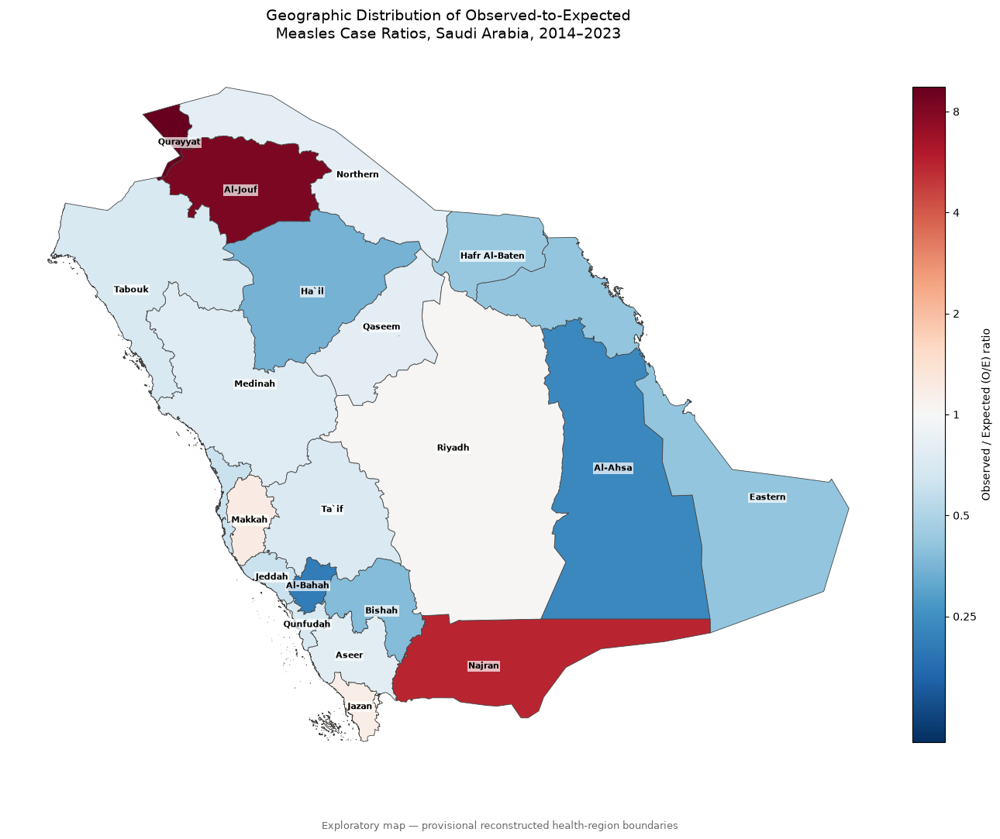

In [28]:

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable

# Log transformation centered at O/E = 1
oe_map["log_oe"] = np.log2(oe_map["oe_ratio"])

# Symmetric color limits around zero
color_limit = np.abs(oe_map["log_oe"]).max()

norm = TwoSlopeNorm(
    vmin=-color_limit,
    vcenter=0,
    vmax=color_limit
)

fig, ax = plt.subplots(figsize=(13, 11))

oe_map.plot(
    column="log_oe",
    cmap="RdBu_r",
    norm=norm,
    ax=ax,
    edgecolor="#444444",
    linewidth=0.6
)

# Label all health regions
for _, row in oe_map.iterrows():

    point = row.geometry.representative_point()

    ax.annotate(
        row["moh_health_region"],
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.7,
            edgecolor="none",
            pad=1
        )
    )

# Colorbar displays original O/E ratios
sm = ScalarMappable(norm=norm, cmap="RdBu_r")
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

oe_ticks = np.array([
    0.25, 0.5, 1, 2, 4, 8
])

oe_ticks = oe_ticks[
    (np.log2(oe_ticks) >= -color_limit)
    & (np.log2(oe_ticks) <= color_limit)
]

cbar.set_ticks(np.log2(oe_ticks))
cbar.set_ticklabels([f"{x:g}" for x in oe_ticks])

cbar.set_label(
    "Observed / Expected (O/E) ratio"
)

ax.set_title(
    "Geographic Distribution of Observed-to-Expected\n"
    "Measles Case Ratios, Saudi Arabia, 2014–2023",
    fontsize=14,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.5, 0.025,
    "Exploratory map — provisional reconstructed health-region boundaries",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])
plt.show()


In [29]:
###################################################
### Geographic Classification of O/E Deviations ###
###################################################

In [30]:

import pandas as pd
import numpy as np

# Previously validated simultaneous null intervals
simultaneous_bounds = pd.DataFrame({
    "health_region": [
        "Qurayyat", "Al-Jouf", "Najran", "Makkah",
        "Jazan", "Riyadh", "Northern", "Qaseem",
        "Aseer", "Medinah", "Ta`if", "Qunfudah",
        "Tabouk", "Jeddah", "Hafr Al-Baten",
        "Eastern", "Bishah", "Ha`il",
        "Al-Ahsa", "Al-Bahah"
    ],
    "lower": [
        0.476706, 0.633515, 0.711815, 0.863708,
        0.822392, 0.933724, 0.635765, 0.814889,
        0.837503, 0.852628, 0.801964, 0.590689,
        0.768480, 0.900676, 0.672383,
        0.885046, 0.628715, 0.740205,
        0.798202, 0.657955
    ],
    "upper": [
        1.523294, 1.366485, 1.288185, 1.136292,
        1.177608, 1.066276, 1.364235, 1.185111,
        1.162497, 1.147372, 1.198036, 1.409311,
        1.231520, 1.099324, 1.327617,
        1.114954, 1.371285, 1.259795,
        1.201798, 1.342045
    ]
})

# Join intervals with the O/E map
categorical_map = oe_map.merge(
    simultaneous_bounds,
    on="health_region",
    how="left",
    validate="one_to_one"
)

assert len(categorical_map) == 20
assert categorical_map[["lower", "upper"]].notna().all().all()

# Assign categories
categorical_map["classification"] = np.select(
    [
        categorical_map["oe_ratio"] > categorical_map["upper"],
        categorical_map["oe_ratio"] < categorical_map["lower"]
    ],
    [
        "Higher than null reference",
        "Lower than null reference"
    ],
    default="Within null reference"
)

print("Regions by classification:")
print(categorical_map["classification"].value_counts())

display(
    categorical_map[
        ["moh_health_region", "oe_ratio",
         "lower", "upper", "classification"]
    ].sort_values("oe_ratio", ascending=False)
)


Regions by classification:
classification
Lower than null reference     12
Higher than null reference     4
Within null reference          4
Name: count, dtype: int64


,moh_health_region,oe_ratio,lower,upper,classification
16,Qurayyat,9.500987,0.476706,1.523294,Higher than null reference
2,Al-Jouf,8.383791,0.633515,1.366485,Higher than null reference
12,Najran,5.551127,0.711815,1.288185,Higher than null reference
10,Makkah,1.193286,0.863708,1.136292,Higher than null reference
8,Jazan,1.159334,0.822392,1.177608,Within null reference
17,Riyadh,1.031918,0.933724,1.066276,Within null reference
13,Northern,0.803333,0.635765,1.364235,Within null reference
14,Qaseem,0.794845,0.814889,1.185111,Lower than null reference
3,Aseer,0.769310,0.837503,1.162497,Lower than null reference
11,Medinah,0.759168,0.852628,1.147372,Lower than null reference


In [31]:

higher = categorical_map[
    categorical_map["classification"] == "Higher than null reference"
]

lower = categorical_map[
    categorical_map["classification"] == "Lower than null reference"
]

within = categorical_map[
    categorical_map["classification"] == "Within null reference"
]

assert (higher["oe_ratio"] > higher["upper"]).all()
assert (lower["oe_ratio"] < lower["lower"]).all()

assert (
    (within["oe_ratio"] >= within["lower"])
    & (within["oe_ratio"] <= within["upper"])
).all()

assert len(higher) + len(lower) + len(within) == 20

print("All classifications validated.")
print("Higher:", len(higher))
print("Within:", len(within))
print("Lower:", len(lower))


All classifications validated.
Higher: 4
Within: 4
Lower: 12


In [32]:

from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare a clean table without geographic geometries
export_table = categorical_map[
    [
        "moh_health_region",
        "observed_cases",
        "expected_cases",
        "oe_ratio",
        "lower",
        "upper",
        "classification"
    ]
].copy()

# Rename columns for readability
export_table.columns = [
    "Health Region",
    "Observed Cases",
    "Expected Cases",
    "O/E Ratio",
    "Simultaneous 95% Null Lower",
    "Simultaneous 95% Null Upper",
    "Classification"
]

# Sort by observed-to-expected ratio
export_table = export_table.sort_values(
    "O/E Ratio", ascending=False
).reset_index(drop=True)

# Export CSV
export_table.to_csv(
    output_dir / "measles_regional_oe_classification.csv",
    index=False,
    float_format="%.6f"
)

# Export Excel
export_table.to_excel(
    output_dir / "measles_regional_oe_classification.xlsx",
    index=False
)

print("CSV and Excel files exported successfully.")
print("Regions exported:", len(export_table))

display(export_table)


CSV and Excel files exported successfully.
Regions exported: 20


,Health Region,Observed Cases,Expected Cases,O/E Ratio,Simultaneous 95% Null Lower,Simultaneous 95% Null Upper,Classification
0,Qurayyat,317,33.364954,9.500987,0.476706,1.523294,Higher than null reference
1,Al-Jouf,567,67.630506,8.383791,0.633515,1.366485,Higher than null reference
2,Najran,603,108.626582,5.551127,0.711815,1.288185,Higher than null reference
3,Makkah,545,456.721932,1.193286,0.863708,1.136292,Higher than null reference
4,Jazan,322,277.745593,1.159334,0.822392,1.177608,Within null reference
5,Riyadh,1600,1550.510950,1.031918,0.933724,1.066276,Within null reference
6,Northern,55,68.464746,0.803333,0.635765,1.364235,Within null reference
7,Qaseem,204,256.653940,0.794845,0.814889,1.185111,Lower than null reference
8,Aseer,253,328.866200,0.769310,0.837503,1.162497,Lower than null reference
9,Medinah,300,395.169558,0.759168,0.852628,1.147372,Lower than null reference


In [33]:
####### ###############
# Create the categorical O/E map

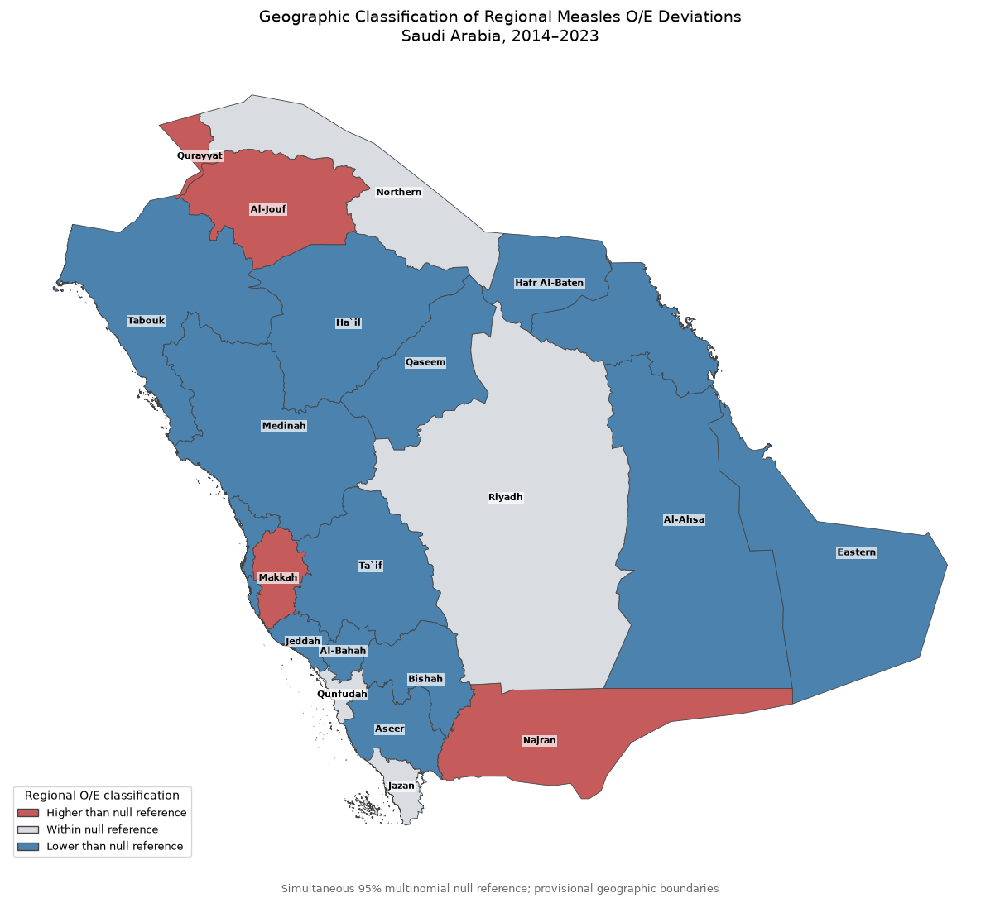

In [34]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Colors for the three classifications
category_colors = {
    "Higher than null reference": "#C65B5B",
    "Within null reference": "#D9DDE2",
    "Lower than null reference": "#4B82AE"
}

# Assign colors to geographic polygons
categorical_map["map_color"] = (
    categorical_map["classification"].map(category_colors)
)

assert categorical_map["map_color"].notna().all()

fig, ax = plt.subplots(figsize=(13, 11))

# Plot classified regions
categorical_map.plot(
    color=categorical_map["map_color"],
    ax=ax,
    edgecolor="#444444",
    linewidth=0.6
)

# Add region names
for _, row in categorical_map.iterrows():

    point = row.geometry.representative_point()

    ax.annotate(
        row["moh_health_region"],
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.7,
            edgecolor="none",
            pad=1
        )
    )

# Create categorical legend
legend_elements = [
    Patch(
        facecolor=color,
        edgecolor="#444444",
        label=category
    )
    for category, color in category_colors.items()
]

ax.legend(
    handles=legend_elements,
    title="Regional O/E classification",
    loc="lower left",
    fontsize=9,
    title_fontsize=10,
    frameon=True
)

ax.set_title(
    "Geographic Classification of Regional Measles O/E Deviations\n"
    "Saudi Arabia, 2014–2023",
    fontsize=14,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.5, 0.025,
    "Simultaneous 95% multinomial null reference; provisional geographic boundaries",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])
plt.show()


In [35]:

print("Total mapped regions:", len(categorical_map))
print("Unique health regions:",
      categorical_map["moh_health_region"].nunique())

print("\nClassification counts:")
print(categorical_map["classification"].value_counts())

print("\nHigher-than-reference regions:")
print(
    categorical_map.loc[
        categorical_map["classification"]
        == "Higher than null reference",
        "moh_health_region"
    ].tolist()
)

print("\nWithin-reference regions:")
print(
    categorical_map.loc[
        categorical_map["classification"]
        == "Within null reference",
        "moh_health_region"
    ].tolist()
)

assert len(categorical_map) == 20
assert categorical_map["moh_health_region"].nunique() == 20
assert categorical_map["classification"].notna().all()


Total mapped regions: 20
Unique health regions: 20

Classification counts:
classification
Lower than null reference     12
Higher than null reference     4
Within null reference          4
Name: count, dtype: int64

Higher-than-reference regions:
['Al-Jouf', 'Makkah', 'Najran', 'Qurayyat']

Within-reference regions:
['Jazan', 'Northern', 'Qunfudah', 'Riyadh']
